# Introduction to Regression: How Much Do Ads Sell?

Welcome to Session 7. In Sessions 5 and 6, you described one variable at a time: how large it was, how it changed, and how it moved through time. Most interesting questions are about **relationships** between variables. If a company shows its ad to more people, how many more sales should it expect? Regression is the standard tool for answering questions like this one.

**Estimated time:** 65-75 minutes

**Dataset:** `northbound_campaigns.csv`, the advertising campaigns of *Northbound Outfitters*, a fictional Canadian online store that sells outdoor gear. Each row is one ad campaign that ran for one week on one advertising channel. The data are **simulated**: they were generated by a program written to behave like real campaign data, so we know the truth behind them and can check what our tools find. We will keep using this file in later sessions for dummy variables, sales efficiency, and forecasting.

By the end, you will be able to describe a relationship with a scatter plot, explain what a line of best fit is and how least squares chooses it, fit a simple regression with `statsmodels`, interpret the intercept, slope, and R-squared in plain language, examine fitted values and residuals, make predictions and recognize when not to trust them, and explain why a single line fitted to mixed groups can give a misleading answer.

## 1. Load the campaign data (5 minutes)

We use the same tools as before, plus one new library. **statsmodels** is a Python library for statistical models; its `formula` interface lets us describe a regression in words, such as `'conversions ~ impressions_k'`. We import it with the short name `smf`.

As in Session 6, the code looks for the CSV in a few common folders. If it cannot find a local copy, it reads the file directly from the course repository on GitHub. We ask pandas to parse `week_start` as a date.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf   # if this fails, run: %pip install statsmodels

file_name = 'northbound_campaigns.csv'
csv_candidates = [
    Path(file_name),
    Path('Data') / file_name,
    Path('../Data') / file_name,
    Path('data') / file_name,
    Path('../data') / file_name,
]
csv_path = next((path for path in csv_candidates if path.exists()), None)
if csv_path is None:
    csv_path = 'https://raw.githubusercontent.com/Brainologist/Python-For-Data-Analytics/main/Data/' + file_name

campaigns = pd.read_csv(csv_path, parse_dates=['week_start'])
print('Loaded:', csv_path)
campaigns.head()

Loaded: ../Data/northbound_campaigns.csv


,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue
0,NB0001,2023-01-02,Social,0,2496.05,355888,3164,65,6125.44
1,NB0002,2023-01-09,Search,0,4512.46,198756,9592,220,20834.90
2,NB0003,2023-01-09,Social,0,2722.19,390272,3793,52,4803.85
3,NB0004,2023-01-09,Display,0,3414.22,1259415,6536,60,5424.96
4,NB0005,2023-01-09,Video,1,4393.00,314891,2885,52,4318.38


## 2. What does one row represent? (6 minutes)

Always answer this question before modelling. Here, one row is **one campaign**: one channel, one week. The columns follow the path from paying for an ad to making a sale.

| Column | Meaning |
| --- | --- |
| `campaign_id` | Campaign identifier |
| `week_start` | Monday the campaign started; each campaign runs for one week |
| `channel` | Where the ad ran: `Search` (ads beside search results), `Social` (social-media feeds), `Display` (banner ads on websites), `Video` (ads before or during online videos) |
| `discount_offer` | 1 if the ad advertised a discount, 0 if not |
| `spend` | Amount paid for the campaign, in Canadian dollars |
| `impressions` | Number of times the ad was shown to someone |
| `clicks` | Number of times someone clicked the ad |
| `conversions` | Number of purchases made by people who clicked |
| `revenue` | Total value of those purchases, in Canadian dollars |

Run the usual checks from Session 5: size, data types, missing values, and a numeric summary.

In [2]:
print('Rows and columns:', campaigns.shape)
print('First week:', campaigns['week_start'].min().date(), '  Last week:', campaigns['week_start'].max().date())
print('Missing values in the whole table:', campaigns.isna().sum().sum())
campaigns.info()

Rows and columns: (441, 9)
First week: 2023-01-02   Last week: 2025-12-29
Missing values in the whole table: 0
<class 'pandas.DataFrame'>
RangeIndex: 441 entries, 0 to 440
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   campaign_id     441 non-null    str           
 1   week_start      441 non-null    datetime64[us]
 2   channel         441 non-null    str           
 3   discount_offer  441 non-null    int64         
 4   spend           441 non-null    float64       
 5   impressions     441 non-null    int64         
 6   clicks          441 non-null    int64         
 7   conversions     441 non-null    int64         
 8   revenue         441 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(4), str(2)
memory usage: 31.1 KB


In [3]:
campaigns.describe().round(1)

,week_start,discount_offer,spend,impressions,clicks,conversions,revenue
count,441,441.0,441.0,441.0,441.0,441.0,441.0
mean,2024-06-24 23:14:17.142857,0.3,4515.4,509781.1,5912.5,162.7,14825.1
min,2023-01-02 00:00:00,0.0,605.7,42012.0,936.0,5.0,526.4
25%,2023-09-25 00:00:00,0.0,2730.4,226455.0,3384.0,52.0,4696.5
50%,2024-06-17 00:00:00,0.0,3992.0,370286.0,4780.0,93.0,8691.8
75%,2025-03-31 00:00:00,1.0,5841.2,642274.0,7328.0,208.0,19089.6
max,2025-12-29 00:00:00,1.0,15587.1,2575538.0,29022.0,940.0,90259.4
std,NaN,0.5,2430.8,421306.8,3767.8,165.5,15085.3


### Rescale impressions

Campaigns are shown hundreds of thousands of times, so "one more impression" is too small a change to think about. Advertisers usually count impressions in thousands. Dividing by 1,000 does not change any relationship in the data; it only changes the units, which will make the regression slope easier to read.

In [4]:
campaigns['impressions_k'] = campaigns['impressions'] / 1000
campaigns[['campaign_id', 'channel', 'impressions', 'impressions_k', 'conversions']].head()

,campaign_id,channel,impressions,impressions_k,conversions
0,NB0001,Social,355888,355.888,65
1,NB0002,Search,198756,198.756,220
2,NB0003,Social,390272,390.272,52
3,NB0004,Display,1259415,1259.415,60
4,NB0005,Video,314891,314.891,52


### Practice 1

How many campaigns ran on each channel? `.value_counts()` counts how often each value appears in a column. Then find the smallest and largest `impressions_k` in the data.

In [5]:
print(campaigns['channel'].value_counts())
print('Smallest campaign (thousand impressions):', campaigns['impressions_k'].min())
print('Largest campaign (thousand impressions):', campaigns['impressions_k'].max())

channel
Search     151
Social     127
Display     90
Video       73
Name: count, dtype: int64
Smallest campaign (thousand impressions): 42.012
Largest campaign (thousand impressions): 2575.538


## 3. Look before you model (7 minutes)

A **scatter plot** places one point for each row: impressions on the horizontal axis and conversions on the vertical axis. The variable we want to explain (conversions) is called the **outcome** or dependent variable. The variable we use to explain it (impressions) is the **predictor** or explanatory variable. By convention, the outcome goes on the vertical axis.

The loop draws each channel in its own colour, so we can see whether channels behave differently.

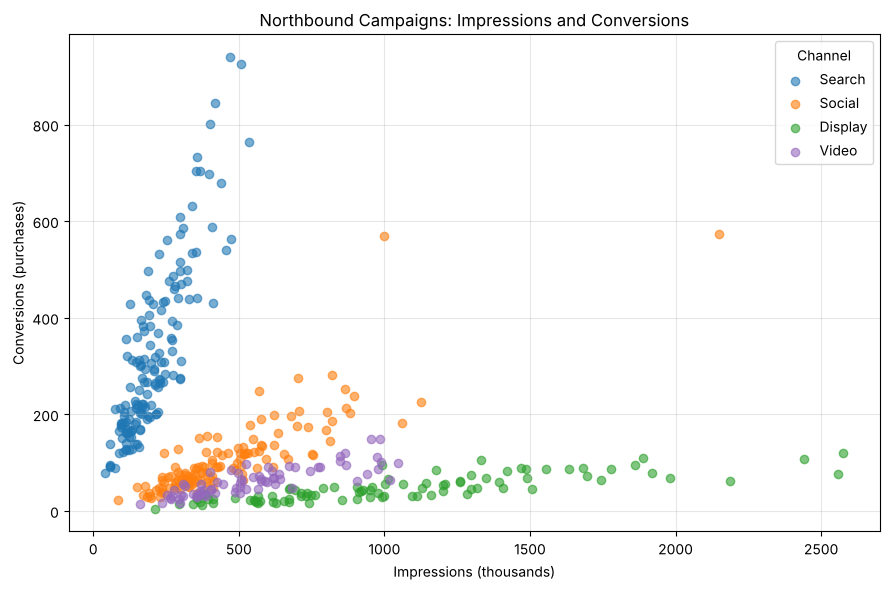

In [6]:
channel_colors = {'Search': 'tab:blue', 'Social': 'tab:orange', 'Display': 'tab:green', 'Video': 'tab:purple'}

plt.figure(figsize=(9, 6))
for channel, color in channel_colors.items():
    rows = campaigns[campaigns['channel'] == channel]
    plt.scatter(rows['impressions_k'], rows['conversions'], color=color, alpha=0.6, label=channel)
plt.title('Northbound Campaigns: Impressions and Conversions')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Conversions (purchases)')
plt.legend(title='Channel')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Each channel forms its own band. Within a band, bigger campaigns tend to produce more purchases. Between bands, the story is different: Display campaigns often show the ad more than a million times and still produce few sales, while Search campaigns produce many sales from far fewer impressions. We will come back to this in Section 9. For now, study one channel at a time, starting with **Search**.

The **correlation** is a single number between -1 and 1 that measures how closely two variables move along a straight line. It is a useful first check, but it does not tell us *how many* extra conversions to expect, which is what a regression line will do.

Search campaigns: 151
Correlation of impressions and conversions: 0.866


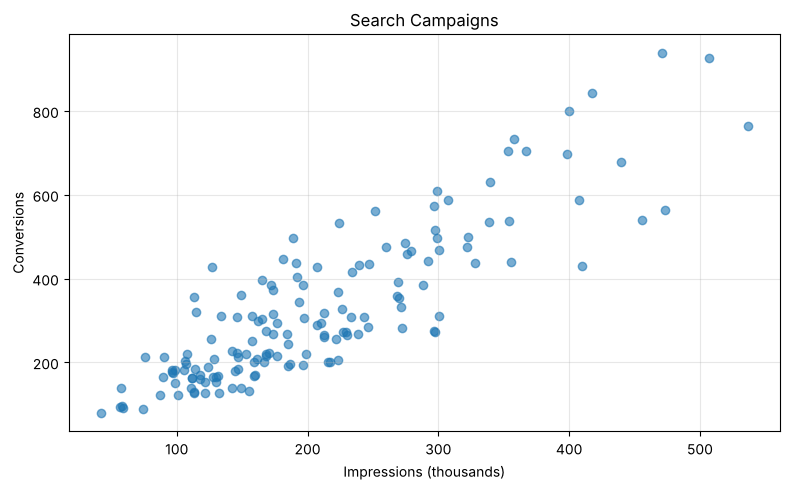

In [7]:
search = campaigns[campaigns['channel'] == 'Search'].copy()
print('Search campaigns:', len(search))
print('Correlation of impressions and conversions:', round(search['impressions_k'].corr(search['conversions']), 3))

plt.figure(figsize=(8, 5))
plt.scatter(search['impressions_k'], search['conversions'], color='tab:blue', alpha=0.6)
plt.title('Search Campaigns')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Conversions')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. The line of best fit (9 minutes)

A simple regression summarizes the cloud of points with a straight line:

$$\text{conversions} = \text{intercept} + \text{slope} \times \text{impressions\_k} + \text{error}$$

- The **slope** is how many more conversions we expect, on average, when a campaign has 1,000 more impressions.
- The **intercept** is the expected number of conversions when impressions are zero, the point where the line crosses the vertical axis.
- The **error** is everything the line does not capture: the week, the ad's wording, chance.

For any line we draw, each campaign has a **residual**: its actual conversions minus the conversions the line predicts. Points above the line have positive residuals; points below have negative ones. **Ordinary least squares (OLS)** chooses the one line that makes the sum of the *squared* residuals as small as possible. Squaring treats misses above and below the line equally and penalizes large misses heavily.

For one predictor, the least-squares line has a short formula. Every piece is a vectorized calculation from Session 4.

In [8]:
x = search['impressions_k']
y = search['conversions']

slope = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
intercept = y.mean() - slope * x.mean()

print(f'Slope: {slope:.3f} conversions per 1,000 impressions')
print(f'Intercept: {intercept:.2f} conversions')

Slope: 1.541 conversions per 1,000 impressions
Intercept: 5.04 conversions


### Why "least squares"?

The function below measures how badly any line fits: it adds up the squared residuals. Compare the least-squares line with a few lines that look reasonable by eye. The least-squares line always has the smallest total.

In [9]:
def sum_squared_residuals(line_intercept, line_slope):
    predicted = line_intercept + line_slope * x
    residuals = y - predicted
    return (residuals ** 2).sum()

candidate_lines = [
    (intercept, slope, 'least squares'),
    (0, 1.5, 'through zero, slope 1.5'),
    (30, 1.4, 'intercept 30, slope 1.4'),
    (-20, 1.65, 'intercept -20, slope 1.65'),
]
for line_intercept, line_slope, description in candidate_lines:
    total = sum_squared_residuals(line_intercept, line_slope)
    print(f'{description:<28} sum of squared residuals = {total:,.0f}')

least squares                sum of squared residuals = 1,215,312
through zero, slope 1.5      sum of squared residuals = 1,245,221
intercept 30, slope 1.4      sum of squared residuals = 1,248,215
intercept -20, slope 1.65    sum of squared residuals = 1,234,438


### Practice 2: beat least squares

Try at least two lines of your own by choosing an intercept and a slope. Can you find a line with a smaller sum of squared residuals than the least-squares line? (You cannot, but try a line very close to it and see how small the difference is.)

In [10]:
print(f"{sum_squared_residuals(0, 1.56):,.0f}")
print(f"{sum_squared_residuals(intercept + 1, slope):,.0f}")
print(f"{sum_squared_residuals(intercept, slope):,.0f}  <- least squares")

1,216,043
1,215,463
1,215,312  <- least squares


## 5. Fit the regression with statsmodels (8 minutes)

In practice, we let a library do the calculation. The formula `'conversions ~ impressions_k'` reads "conversions explained by impressions_k". statsmodels adds the intercept automatically. `.fit()` estimates the line and returns a results object that we store as `model`.

In [11]:
model = smf.ols('conversions ~ impressions_k', data=search).fit()

print(model.params)
print('R-squared:', round(model.rsquared, 3))

Intercept        5.039835
impressions_k    1.540643
dtype: float64
R-squared: 0.749


The intercept and slope match the values we calculated by hand. **R-squared** is the share of the variation in conversions across Search campaigns that the line accounts for. It runs from 0 (the line explains nothing) to 1 (every point lies exactly on the line). Here, campaign size explains roughly three-quarters of the differences in sales between Search campaigns; the rest comes from things the line leaves out.

`model.summary()` prints the full results table. It contains much more than we need today. Focus on these parts:

- `coef`: the estimated intercept and slope.
- `std err`: how much the estimate would likely vary if we had a different sample of campaigns. Smaller means more precise.
- `P>|t|`: the p-value for the question "could the true value be zero?" A value near 0 means the data give strong evidence that it is not zero.
- `[0.025  0.975]`: a 95% confidence interval, a range of plausible values for the true intercept or slope.
- `R-squared` and `No. Observations` in the top panel.

In [12]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            conversions   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     444.9
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.38e-46
Time:                        12:51:59   Log-Likelihood:                -893.25
No. Observations:                 151   AIC:                             1790.
Df Residuals:                     149   BIC:                             1797.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         5.0398     16.835      0.299      0.765     -28.225      38.305
impressions_k     1.5406      0.073     21.092      0.000       1.396       1.685
==============================================================================
Omnibus:                        3.102   Durbin-Watson:                   1.357
Prob(Omnibus):                  0.212   Jarque-Bera (JB):                3.114
Skew:                           0.342   Prob(JB):                        0.211
Kurtosis:                       2.837   Cond. No.                         528.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Say it in words

A regression result is only useful if you can state it plainly. The f-string below pulls the numbers from the model so the sentence updates if the data change.

In [13]:
b0 = model.params['Intercept']
b1 = model.params['impressions_k']
low, high = model.conf_int().loc['impressions_k']

print(f'Each additional 1,000 impressions on Search is associated with about {b1:.2f} more purchases.')
print(f'A 95% confidence interval for that slope runs from {low:.2f} to {high:.2f}.')
print(f'Put differently, roughly {1000 / b1:.0f} impressions per purchase at the margin.')
print(f'The line explains {model.rsquared:.0%} of the variation in conversions across {int(model.nobs)} campaigns.')

Each additional 1,000 impressions on Search is associated with about 1.54 more purchases.
A 95% confidence interval for that slope runs from 1.40 to 1.68.
Put differently, roughly 649 impressions per purchase at the margin.
The line explains 75% of the variation in conversions across 151 campaigns.


**Association or effect?** The slope describes how conversions and impressions move together in these data. It measures the *effect* of showing more ads only if nothing else changes along with campaign size. In real companies, that is often not true: managers may give bigger budgets to weeks they already expect to sell well, such as the holiday season, and part of the slope would then reflect the season rather than the ads. Because these data are simulated, we know budgets were set without looking at the season, but with real data you would have to argue for it.

The intercept is close to zero, which makes sense: no impressions, no ad-driven purchases. It is not exactly zero because the line is estimated from noisy data, and its confidence interval includes zero.

## 6. Fitted values and residuals (8 minutes)

The model stores, for every campaign, the line's prediction (`fittedvalues`) and the miss (`resid`). Residual equals actual minus fitted. Add both as columns so we can study them.

In [14]:
search['fitted'] = model.fittedvalues
search['residual'] = model.resid

one_decimal = {'impressions_k': 1, 'fitted': 1, 'residual': 1}
search[['week_start', 'impressions_k', 'conversions', 'fitted', 'residual']].head().round(one_decimal)

,week_start,impressions_k,conversions,fitted,residual
1,2023-01-09,198.8,220,311.3,-91.3
5,2023-01-16,131.6,167,207.8,-40.8
7,2023-01-23,221.9,256,346.9,-90.9
10,2023-01-30,226.8,273,354.5,-81.5
12,2023-02-06,226.5,327,353.9,-26.9


Draw the line over the data. Sorting by impressions first makes Matplotlib connect the fitted points from left to right.

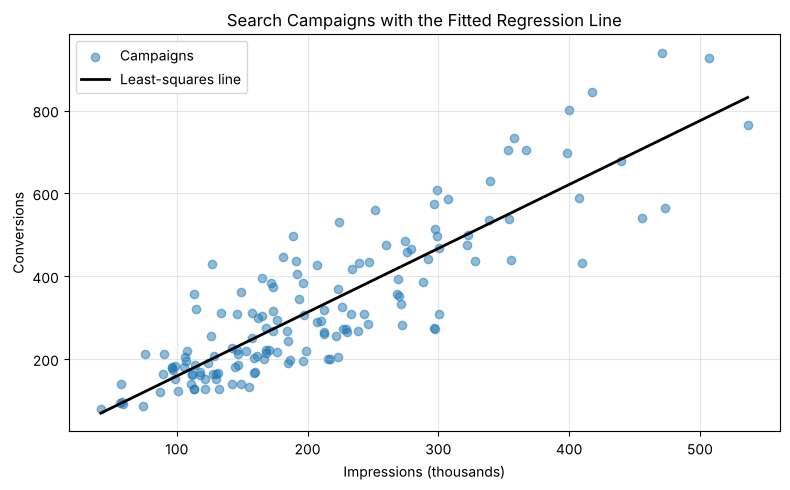

In [15]:
line_data = search.sort_values('impressions_k')

plt.figure(figsize=(8, 5))
plt.scatter(search['impressions_k'], search['conversions'], color='tab:blue', alpha=0.5, label='Campaigns')
plt.plot(line_data['impressions_k'], line_data['fitted'], color='black', linewidth=2, label='Least-squares line')
plt.title('Search Campaigns with the Fitted Regression Line')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Conversions')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### The residual plot

A residual plot puts the residuals on the vertical axis. If a straight line is a good description, the points should scatter around zero with no clear curve. Look for two things: a **curved pattern** (the relationship is not a straight line) and a **funnel** (misses get larger as campaigns get larger).

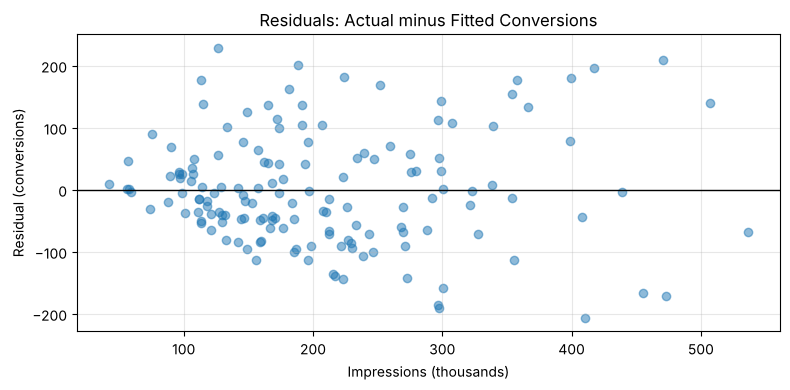

In [16]:
plt.figure(figsize=(8, 4))
plt.scatter(search['impressions_k'], search['residual'], color='tab:blue', alpha=0.5)
plt.axhline(0, color='black', linewidth=1)
plt.title('Residuals: Actual minus Fitted Conversions')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Residual (conversions)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

There is no obvious curve, so a straight line is a reasonable summary. The spread is somewhat wider for larger campaigns: a campaign predicted to make 600 sales can easily miss by 150, while one predicted to make 100 cannot. This pattern is common in sales data. It does not move the line, but it affects how precise the standard errors are; later courses show how to adjust for it.

Residuals are also useful for business: they identify campaigns that did better or worse than their size alone would suggest.

In [17]:
columns = ['week_start', 'discount_offer', 'impressions_k', 'conversions', 'fitted', 'residual']
print('Campaigns that beat the line by the most:')
search.sort_values('residual', ascending=False)[columns].head(8).round(one_decimal)

Campaigns that beat the line by the most:


,week_start,discount_offer,impressions_k,conversions,fitted,residual
341,2025-04-28,1,126.8,429,200.4,228.6
434,2025-12-15,0,470.6,940,730.1,209.9
438,2025-12-29,0,188.6,497,295.6,201.4
96,2023-08-21,0,417.4,844,648.2,195.8
142,2023-12-04,1,224.3,532,350.6,181.4
332,2025-04-07,0,399.7,801,620.9,180.1
427,2025-12-01,0,357.8,734,556.3,177.7
113,2023-10-02,1,113.3,357,179.6,177.4


### Practice 3: the disappointing campaigns

Display the eight Search campaigns with the most **negative** residuals. Then look at the two lists together. In which months did the best campaigns run? How many of the worst campaigns offered a discount? What does that suggest our one-predictor line is leaving out?

In [18]:
worst = search.sort_values('residual')[columns].head(8)
display(worst.round(one_decimal))
print('Worst campaigns that offered a discount:', worst['discount_offer'].sum(), 'of', len(worst))

,week_start,discount_offer,impressions_k,conversions,fitted,residual
70,2023-06-26,0,410.2,431,636.9,-205.9
159,2024-01-22,0,297.7,273,463.7,-190.7
231,2024-07-15,0,296.7,276,462.2,-186.2
276,2024-11-04,0,473.4,564,734.4,-170.4
311,2025-02-17,0,455.4,541,706.7,-165.7
34,2023-04-03,0,300.4,310,467.8,-157.8
17,2023-02-20,0,223.2,205,349.0,-144.0
212,2024-05-27,0,272.4,282,424.8,-142.8


Worst campaigns that offered a discount: 0 of 8


None of the worst campaigns offered a discount, while three of the best did. The best campaigns also cluster in December and April, and several ran in the most recent year. Season, discounts, and time are all information the line ignores. Adding them to the model is the job of **multiple regression** and **dummy variables**, which come next.

## 7. Use the line to predict (7 minutes)

A fitted line can predict the outcome for new values of the predictor. Suppose the marketing team is planning three Search campaigns of 150, 300, and 450 thousand impressions. `.predict()` needs a DataFrame with a column of the same name as the predictor.

In [19]:
planned = pd.DataFrame({'impressions_k': [150, 300, 450]})
planned['predicted_conversions'] = model.predict(planned)
planned.round(1)

,impressions_k,predicted_conversions
0,150,236.1
1,300,467.2
2,450,698.3


A single number hides how uncertain a prediction is. `.get_prediction()` also gives a **95% prediction interval**: a range that should contain the actual conversions of about 95 out of 100 new campaigns of that size. It is wide because individual campaigns vary a lot around the line (look at the residual plot again). The interval assumes the misses are equally spread for campaigns of every size; since the spread grows with size, treat it as a rough guide, a little too wide for small campaigns and a little too narrow for large ones.

In [20]:
prediction = model.get_prediction(planned[['impressions_k']]).summary_frame(alpha=0.05)
prediction['impressions_k'] = planned['impressions_k']
prediction[['impressions_k', 'mean', 'obs_ci_lower', 'obs_ci_upper']].round(0)

,impressions_k,mean,obs_ci_lower,obs_ci_upper
0,150,236.0,57.0,415.0
1,300,467.0,288.0,647.0
2,450,698.0,516.0,881.0


### Do not extrapolate blindly

The Search campaigns in our data range from about 40 to about 540 thousand impressions. The line has only been checked inside that range. The code below predicts a campaign of 3 million impressions. Python gives an answer without complaint, but nothing in the data tells us whether the straight line still holds that far out. In real advertising it usually does not: once the ad has reached the people most likely to buy, extra impressions reach people who are less interested, and each additional thousand impressions produces fewer sales.

In [21]:
print('Observed range:', round(search['impressions_k'].min()), 'to', round(search['impressions_k'].max()), 'thousand impressions')
huge = pd.DataFrame({'impressions_k': [3000]})
print('Line prediction for 3,000 thousand impressions:', round(model.predict(huge).iloc[0]), 'conversions (do not trust this)')

Observed range: 42 to 536 thousand impressions
Line prediction for 3,000 thousand impressions: 4627 conversions (do not trust this)


## 8. Same question, every channel (7 minutes)

A loop can fit the same regression for each channel and collect the results, combining loops and dictionaries from Session 2 with the model from this session. The slope is the number of **extra conversions per 1,000 extra impressions** on that channel.

We also calculate each channel's **cost per 1,000 impressions** (often called CPM): total spend divided by total impressions in thousands. Dividing the cost of 1,000 impressions by the conversions they produce gives the approximate **cost of one extra conversion** on each channel.

In [22]:
channel_results = []
for channel in channel_colors:
    rows = campaigns[campaigns['channel'] == channel]
    fit = smf.ols('conversions ~ impressions_k', data=rows).fit()
    channel_results.append({
        'channel': channel,
        'campaigns': int(fit.nobs),
        'intercept': fit.params['Intercept'],
        'conversions_per_1000_impressions': fit.params['impressions_k'],
        'r_squared': fit.rsquared,
        'cost_per_1000_impressions': rows['spend'].sum() / rows['impressions_k'].sum(),
    })

results = pd.DataFrame(channel_results).set_index('channel')
results['cost_per_extra_conversion'] = results['cost_per_1000_impressions'] / results['conversions_per_1000_impressions']
results.round(3)

,campaigns,intercept,conversions_per_1000_impressions,r_squared,cost_per_1000_impressions,cost_per_extra_conversion
channel,,,,,,
Search,151,5.040,1.541,0.749,24.229,15.727
Social,127,-17.283,0.274,0.727,8.109,29.624
Display,90,3.249,0.042,0.694,2.964,70.103
Video,73,3.504,0.106,0.677,11.826,111.122


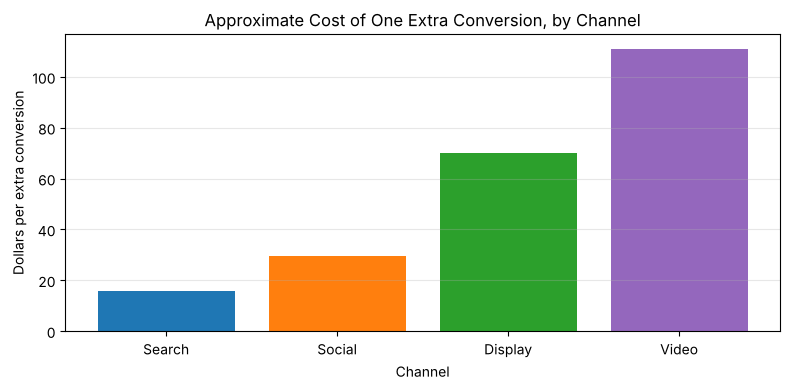

In [23]:
plt.figure(figsize=(8, 4))
plt.bar(results.index, results['cost_per_extra_conversion'], color=[channel_colors[c] for c in results.index])
plt.title('Approximate Cost of One Extra Conversion, by Channel')
plt.xlabel('Channel')
plt.ylabel('Dollars per extra conversion')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Display has the cheapest impressions but some of the most expensive conversions, because so few people who see a banner ad go on to buy. Search impressions are the most expensive, yet Search buys a sale for the lowest cost. **Cheap attention is not the same as cheap sales.** In a later session we will measure efficiency directly with cost per acquisition and return on ad spend; the regression slopes give a first, marginal view of the same question.

## 9. A warning: one line for everything (6 minutes)

What if we skip Section 3's advice and fit one line to all campaigns together, ignoring the channel?

In [24]:
pooled = smf.ols('conversions ~ impressions_k', data=campaigns).fit()
print(f"Pooled slope: {pooled.params['impressions_k']:.3f} conversions per 1,000 impressions")
print(f"Pooled R-squared: {pooled.rsquared:.3f}")

Pooled slope: -0.089 conversions per 1,000 impressions
Pooled R-squared: 0.051


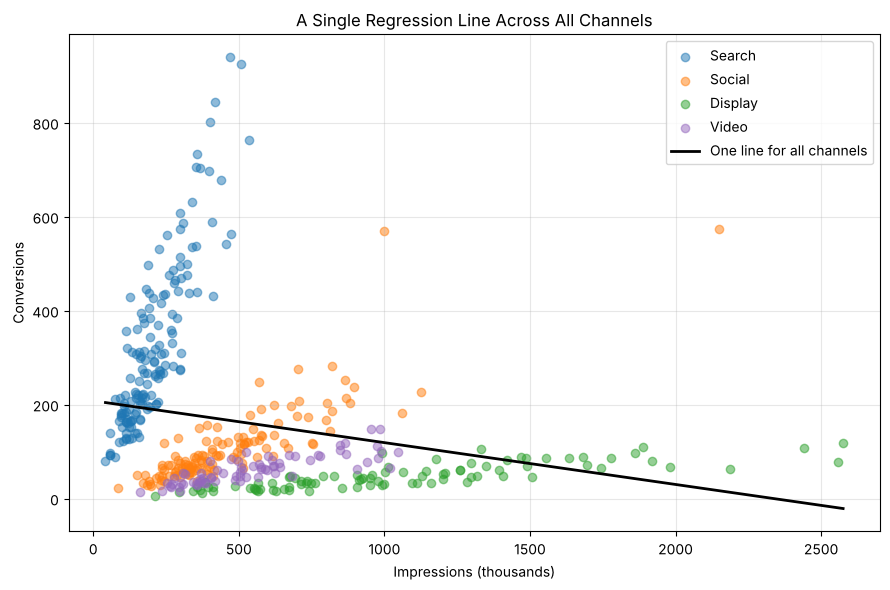

In [25]:
x_grid = pd.DataFrame({'impressions_k': [campaigns['impressions_k'].min(), campaigns['impressions_k'].max()]})

plt.figure(figsize=(9, 6))
for channel, color in channel_colors.items():
    rows = campaigns[campaigns['channel'] == channel]
    plt.scatter(rows['impressions_k'], rows['conversions'], color=color, alpha=0.5, label=channel)
plt.plot(x_grid['impressions_k'], pooled.predict(x_grid), color='black', linewidth=2, label='One line for all channels')
plt.title('A Single Regression Line Across All Channels')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Conversions')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The pooled slope is **negative**: taken at face value, it says that showing an ad more often *reduces* sales. Yet within every single channel, the slope is clearly positive. The pooled line is not comparing bigger and smaller campaigns of the same kind. It is mostly comparing *channels*: the campaigns with the most impressions are Display campaigns, which convert rarely, and the campaigns with the fewest impressions are Search campaigns, which convert often. The channel is related to both impressions and conversions, and leaving it out of the model distorts the slope. Economists call this **omitted variable bias**.

The fix is not to stop using regression, but to tell the model which channel each campaign belongs to. That is exactly what **dummy variables** do, and they are the next step in this series. The lesson for today: a regression only answers the question that the data you give it can answer, so always look at the data first.

## 10. Mini-project: what does an extra advertising dollar return? (8 minutes)

The marketing team cares less about impressions than about money. Use regression to answer their question in dollars:

1. Using only Search campaigns, fit a regression of `revenue` on `spend`. Interpret the slope in one sentence: what does one extra dollar of Search spending return in revenue, on average?
2. Repeat for Social campaigns.
3. Revenue is not profit: the company must still pay for the goods it sells. Suppose Northbound keeps 40 cents of gross profit from each dollar of revenue. Then an extra advertising dollar pays for itself only if it brings in at least 1 / 0.40 = 2.50 dollars of revenue. According to your slopes, which channels clear that bar?
4. Make a scatter plot of revenue against spend for one channel with its fitted line.
5. Name one reason the slope might overstate what the company would earn by raising its budget.

Try your own code before looking at the example solution.

In [26]:
# Write your solution here. Start by selecting the Search campaigns.

### Example solution

Run this after attempting the questions. Then adapt it to compare Display and Video.

Search: each extra $1 of spend is associated with $5.81 of revenue (R-squared 0.72); this clears the $2.50 break-even.
Social: each extra $1 of spend is associated with $3.03 of revenue (R-squared 0.69); this clears the $2.50 break-even.


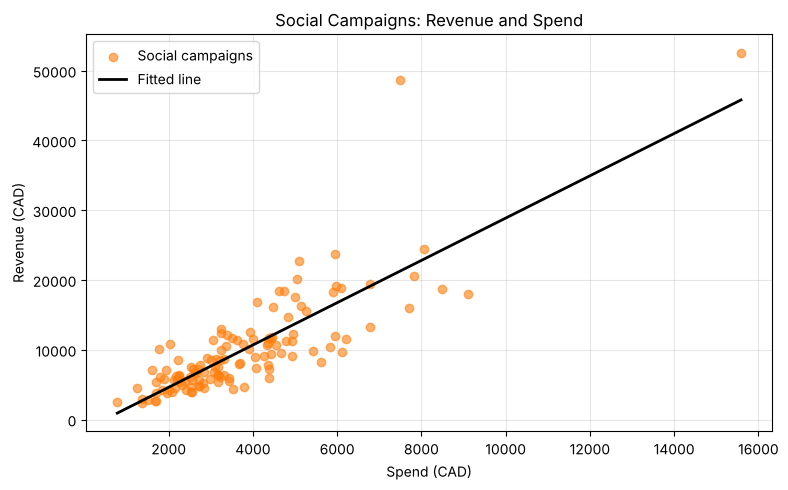

In [27]:
break_even_slope = 1 / 0.40

for channel in ['Search', 'Social']:
    rows = campaigns[campaigns['channel'] == channel]
    money_model = smf.ols('revenue ~ spend', data=rows).fit()
    dollars_back = money_model.params['spend']
    verdict = 'clears' if dollars_back > break_even_slope else 'does not clear'
    print(f'{channel}: each extra $1 of spend is associated with ${dollars_back:.2f} of revenue '
          f'(R-squared {money_model.rsquared:.2f}); this {verdict} the ${break_even_slope:.2f} break-even.')

social = campaigns[campaigns['channel'] == 'Social'].copy()
social_model = smf.ols('revenue ~ spend', data=social).fit()
social['fitted_revenue'] = social_model.fittedvalues
social = social.sort_values('spend')

plt.figure(figsize=(8, 5))
plt.scatter(social['spend'], social['revenue'], color='tab:orange', alpha=0.6, label='Social campaigns')
plt.plot(social['spend'], social['fitted_revenue'], color='black', linewidth=2, label='Fitted line')
plt.title('Social Campaigns: Revenue and Spend')
plt.xlabel('Spend (CAD)')
plt.ylabel('Revenue (CAD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

One answer to question 5: the slope is estimated from campaigns between roughly \$1,000 and \$15,000. Raising budgets beyond that range is extrapolation, and returns usually shrink as a campaign reaches less interested customers. Another: if bigger budgets tended to run in strong sales weeks, part of the slope would reflect those weeks rather than the extra spending.

## Recap

A scatter plot shows how two variables move together; look at it before fitting anything. A simple regression summarizes the relationship with a straight line chosen by ordinary least squares, the line with the smallest sum of squared residuals. The slope is the expected change in the outcome for a one-unit change in the predictor, so choose units that make it readable. R-squared measures the share of variation the line explains. Residuals show what the line misses and can point to the variables it leaves out. Predictions come with uncertainty and should not be trusted far outside the observed data. Finally, a single line fitted across different groups can reverse the true within-group relationship; the next session adds dummy variables to handle exactly this.